# 🏛️ Elkem ASA Technology — CSV & Primavera P6 Banana Curve Analysenotebook
Denne notebooken analyserer prosjektdataene for **CA-5020 (Carbon-Neutral Smelter Pilot)**, inkludert SkatteFUNN, IFRS 15, EVM og **Primavera P6 Banana-kurver**.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data_dir = './data' if os.path.exists('./data') else '.'
print(f'Datamappe: {data_dir}')

Datamappe: ./data


## 🍌 1. Primavera P6 Banana Curve (Early Start vs. Late Start S-Kurver)
Banana-kurven viser handlingsrommet mellom øvre grense (**Early Start**) og nedre grense (**Late Start**). Så lenge faktisk fremdrift (EV) ligger inne i 'bananen', er prosjektet innenfor godkjent totalslakk.

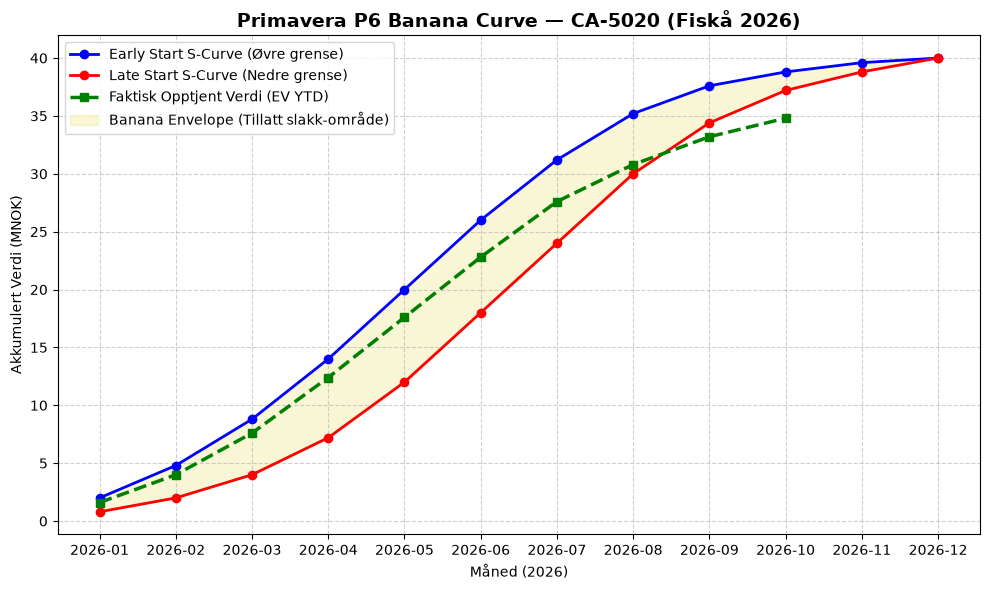

In [2]:
# Lag eller les inn Banana Curve data
months = [f'2026-{m:02d}' for m in range(1, 13)]
bac = 40.0 # MNOK

early_pct = np.array([0.05, 0.12, 0.22, 0.35, 0.50, 0.65, 0.78, 0.88, 0.94, 0.97, 0.99, 1.00])
late_pct  = np.array([0.02, 0.05, 0.10, 0.18, 0.30, 0.45, 0.60, 0.75, 0.86, 0.93, 0.97, 1.00])
actual_pct = np.array([0.04, 0.10, 0.19, 0.31, 0.44, 0.57, 0.69, 0.77, 0.83, 0.87, np.nan, np.nan])

df_banana = pd.DataFrame({
    'Month': months,
    'Early_Start_MNOK': early_pct * bac,
    'Late_Start_MNOK': late_pct * bac,
    'Actual_EV_MNOK': actual_pct * bac
})

# Visualisering
plt.figure(figsize=(10, 6))
plt.plot(df_banana['Month'], df_banana['Early_Start_MNOK'], 'b-o', label='Early Start S-Curve (Øvre grense)', linewidth=2)
plt.plot(df_banana['Month'], df_banana['Late_Start_MNOK'], 'r-o', label='Late Start S-Curve (Nedre grense)', linewidth=2)
plt.plot(df_banana['Month'], df_banana['Actual_EV_MNOK'], 'g--s', label='Faktisk Opptjent Verdi (EV YTD)', linewidth=2.5)

plt.fill_between(df_banana['Month'], df_banana['Late_Start_MNOK'], df_banana['Early_Start_MNOK'], color='khaki', alpha=0.35, label='Banana Envelope (Tillatt slakk-område)')
plt.title('Primavera P6 Banana Curve — CA-5020 (Fiskå 2026)', fontsize=14, fontweight='bold')
plt.xlabel('Måned (2026)')
plt.ylabel('Akkumulert Verdi (MNOK)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

## ⏱️ 2. SkatteFUNN Timesatsavskjæring (Maks 530 kr/t)
Avskjæringsanalyse for å sikre etterlevelse av SkatteFUNN-reglene.

In [3]:
ts_file = os.path.join(data_dir, '02_hr_timesheets_line_items.csv')
if os.path.exists(ts_file):
    df_ts = pd.read_csv(ts_file)
    summary = df_ts.groupby(['Employee_Name', 'Role']).agg(
        Total_Hours=('Hours_Logged', 'sum'),
        Nominal_Rate=('Nominal_Hourly_Rate_NOK', 'first'),
        Capped_Rate=('SkatteFUNN_Capped_Rate_NOK', 'first')
    ).reset_index()
    summary['Disallowed_NOK'] = (summary['Nominal_Rate'] - summary['Capped_Rate']) * summary['Total_Hours']
    display(summary)
else:
    print('HR Timesheets file not found.')

,Employee_Name,Role,Total_Hours,Nominal_Rate,Capped_Rate,Disallowed_NOK
0,Dr. Håkon Olsen,Senior Principal Scientist,1657,680,530,248550
1,Janne Bergan,Pilot Test Engineer,1666,480,480,0
2,Knut Arnesen,Senior Process Engineer,1670,590,530,100200
3,Lars Tangen,Lab Technician,1667,420,420,0
4,Svein Viken,Automation & Sensor Specialist,1672,520,520,0
